<h1><center>Rainfall Prediction</center></h1>

## Import the Libraries

In [1]:
# importing the required libraries 
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics

## Read the Data

In [2]:
# reading the data
data = pd.read_csv("rainfall in india 1901-2015.csv")
data.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,ANDAMAN & NICOBAR ISLANDS,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,ANDAMAN & NICOBAR ISLANDS,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


## Data Exploration and Pre-Processing

In [3]:
data.shape

(4116, 19)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4116 entries, 0 to 4115
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4116 non-null   object 
 1   YEAR         4116 non-null   int64  
 2   JAN          4112 non-null   float64
 3   FEB          4113 non-null   float64
 4   MAR          4110 non-null   float64
 5   APR          4112 non-null   float64
 6   MAY          4113 non-null   float64
 7   JUN          4111 non-null   float64
 8   JUL          4109 non-null   float64
 9   AUG          4112 non-null   float64
 10  SEP          4110 non-null   float64
 11  OCT          4109 non-null   float64
 12  NOV          4105 non-null   float64
 13  DEC          4106 non-null   float64
 14  ANNUAL       4090 non-null   float64
 15  Jan-Feb      4110 non-null   float64
 16  Mar-May      4107 non-null   float64
 17  Jun-Sep      4106 non-null   float64
 18  Oct-Dec      4103 non-null   float64
dtypes: flo

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
YEAR,4116.0,1958.218659,33.140898,1901.0,1930.000,1958.0,1987.000,2015.0
JAN,4112.0,18.957320,33.585371,0.0,0.600,6.0,22.200,583.7
FEB,4113.0,21.805325,35.909488,0.0,0.600,6.7,26.800,403.5
MAR,4110.0,27.359197,46.959424,0.0,1.000,7.8,31.300,605.6
APR,4112.0,43.127432,67.831168,0.0,3.000,15.7,49.950,595.1
MAY,4113.0,85.745417,123.234904,0.0,8.600,36.6,97.200,1168.6
JUN,4111.0,230.234444,234.710758,0.4,70.350,138.7,305.150,1609.9
JUL,4109.0,347.214334,269.539667,0.0,175.600,284.8,418.400,2362.8
AUG,4112.0,290.263497,188.770477,0.0,155.975,259.4,377.800,1664.6
SEP,4110.0,197.361922,135.408345,0.1,100.525,173.9,265.800,1222.0


In [6]:
data.isnull().sum()

SUBDIVISION     0
YEAR            0
JAN             4
FEB             3
MAR             6
APR             4
MAY             3
JUN             5
JUL             7
AUG             4
SEP             6
OCT             7
NOV            11
DEC            10
ANNUAL         26
Jan-Feb         6
Mar-May         9
Jun-Sep        10
Oct-Dec        13
dtype: int64

In [7]:
data.duplicated().sum()

0

In [8]:
data['SUBDIVISION'].value_counts()

SUBDIVISION
WEST MADHYA PRADESH                   115
EAST RAJASTHAN                        115
COASTAL KARNATAKA                     115
TAMIL NADU                            115
RAYALSEEMA                            115
TELANGANA                             115
COASTAL ANDHRA PRADESH                115
CHHATTISGARH                          115
VIDARBHA                              115
MATATHWADA                            115
MADHYA MAHARASHTRA                    115
KONKAN & GOA                          115
SAURASHTRA & KUTCH                    115
GUJARAT REGION                        115
EAST MADHYA PRADESH                   115
KERALA                                115
WEST RAJASTHAN                        115
SOUTH INTERIOR KARNATAKA              115
JAMMU & KASHMIR                       115
HIMACHAL PRADESH                      115
PUNJAB                                115
HARYANA DELHI & CHANDIGARH            115
UTTARAKHAND                           115
WEST UTTAR PRADESH    

In [9]:
numeric_data = data.select_dtypes(include='number')
mean_values = numeric_data.mean()
print(mean_values)

YEAR       1958.218659
JAN          18.957320
FEB          21.805325
MAR          27.359197
APR          43.127432
MAY          85.745417
JUN         230.234444
JUL         347.214334
AUG         290.263497
SEP         197.361922
OCT          95.507009
NOV          39.866163
DEC          18.870580
ANNUAL     1411.008900
Jan-Feb      40.747786
Mar-May     155.901753
Jun-Sep    1064.724769
Oct-Dec     154.100487
dtype: float64


In [10]:
# filling null values with mean
# Step 1: Select numeric columns
numeric_cols = data.select_dtypes(include='number').columns

# Step 2: Fill NaN/null values in numeric columns with the mean
data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].mean())


In [11]:
data.head(3)

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6


In [12]:
data.isnull().any()

SUBDIVISION    False
YEAR           False
JAN            False
FEB            False
MAR            False
APR            False
MAY            False
JUN            False
JUL            False
AUG            False
SEP            False
OCT            False
NOV            False
DEC            False
ANNUAL         False
Jan-Feb        False
Mar-May        False
Jun-Sep        False
Oct-Dec        False
dtype: bool

In [13]:
data.YEAR.unique()

array([1901, 1902, 1903, 1904, 1905, 1906, 1907, 1908, 1910, 1911, 1912,
       1913, 1914, 1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922, 1923,
       1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934,
       1935, 1936, 1937, 1938, 1939, 1940, 1941, 1942, 1946, 1947, 1949,
       1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960,
       1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971,
       1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982,
       1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993,
       1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004,
       2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015,
       1943, 1944, 1945, 1948, 1909], dtype=int64)

In [14]:
data.describe()

,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
count,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000,4116.000000
mean,1958.218659,18.957320,21.805325,27.359197,43.127432,85.745417,230.234444,347.214334,290.263497,197.361922,95.507009,39.866163,18.870580,1411.008900,40.747786,155.901753,1064.724769,154.100487
std,33.140898,33.569044,35.896396,46.925176,67.798192,123.189974,234.568120,269.310313,188.678707,135.309591,99.434452,68.593545,42.318098,900.986632,59.265023,201.096692,706.881054,166.678751
min,1901.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.400000,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,62.300000,0.000000,0.000000,57.400000,0.000000
25%,1930.000000,0.600000,0.600000,1.000000,3.000000,8.600000,70.475000,175.900000,156.150000,100.600000,14.600000,0.700000,0.100000,806.450000,4.100000,24.200000,574.375000,34.200000
50%,1958.000000,6.000000,6.700000,7.900000,15.700000,36.700000,138.900000,284.900000,259.500000,174.100000,65.750000,9.700000,3.100000,1125.450000,19.300000,75.200000,882.250000,98.800000
75%,1987.000000,22.125000,26.800000,31.225000,49.825000,96.825000,304.950000,418.225000,377.725000,265.725000,148.300000,45.825000,17.700000,1635.100000,50.300000,196.900000,1287.550000,212.600000
max,2015.000000,583.700000,403.500000,605.600000,595.100000,1168.600000,1609.900000,2362.800000,1664.600000,1222.000000,948.300000,648.900000,617.500000,6331.100000,699.500000,1745.800000,4536.900000,1252.500000


In [15]:
data.shape

(4116, 19)

## Data Visualization

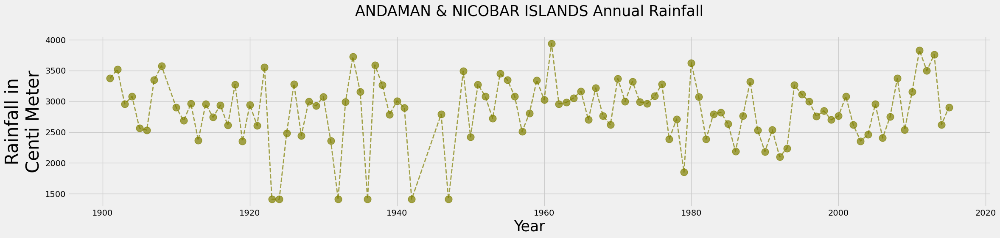

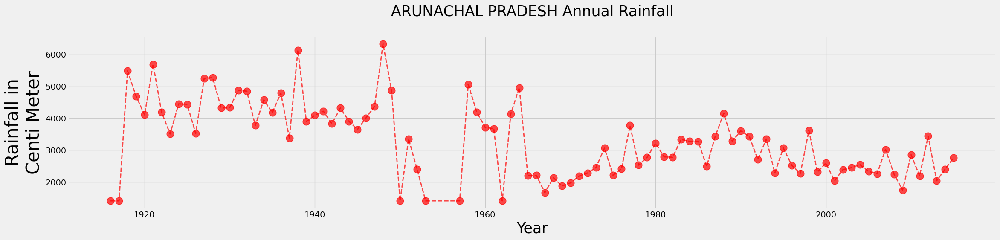

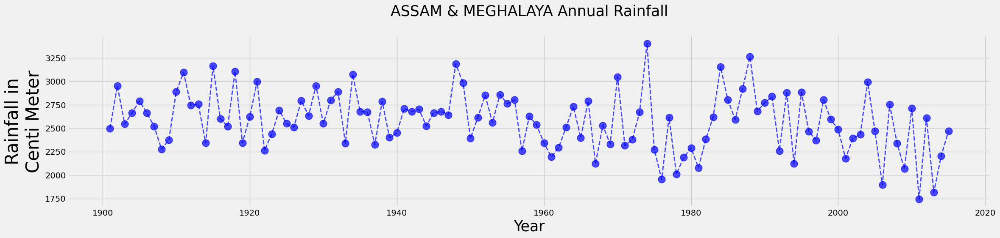

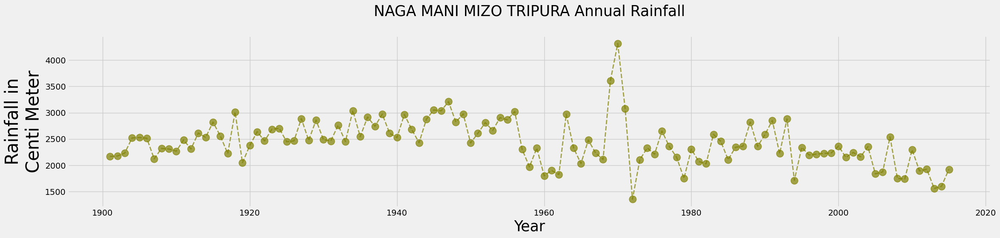

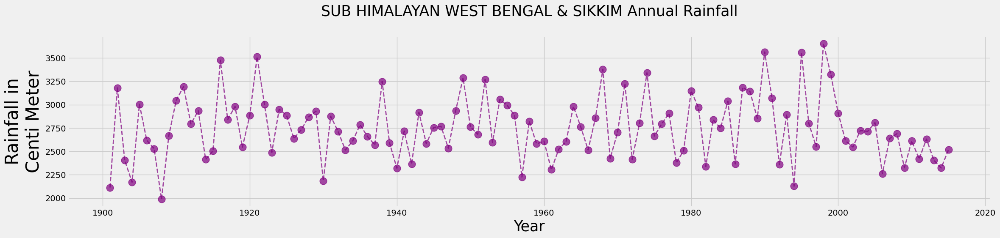

...

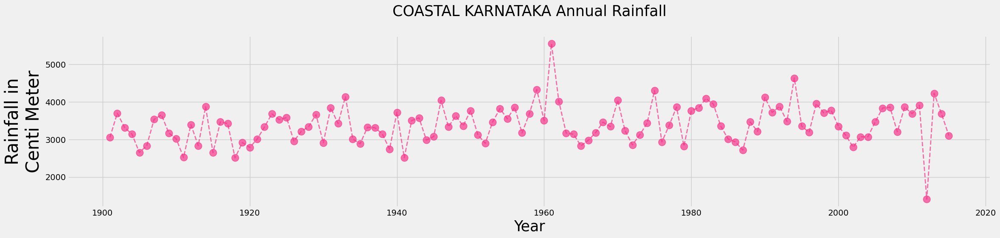

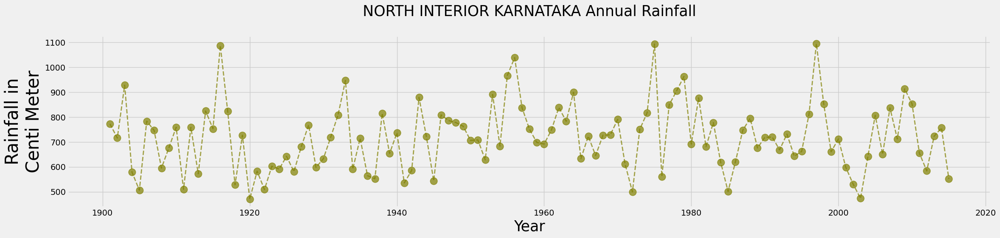

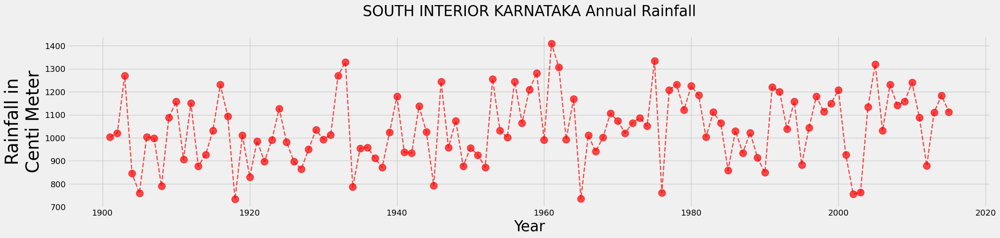

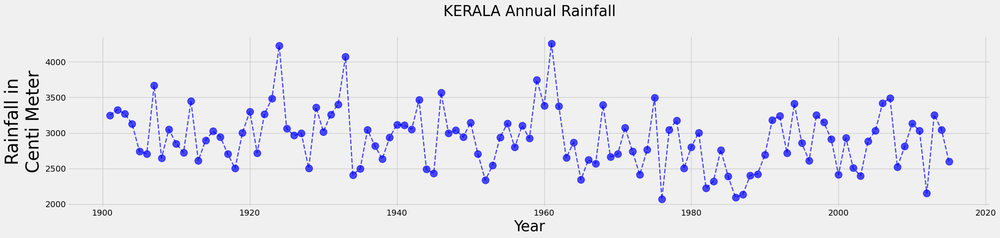

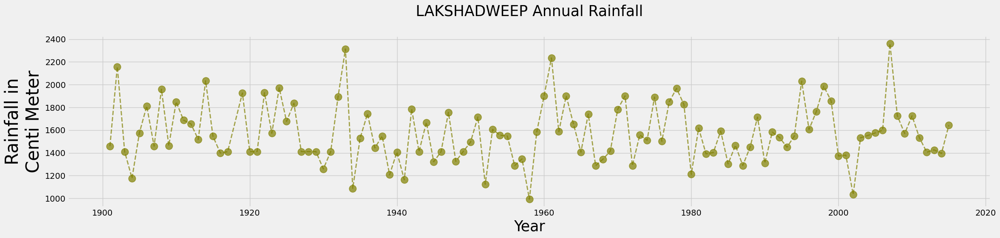

In [16]:
def _SUBDIVISION(column,division):
        Year = []
        annual = []
        for i in range(len(column)):
            if column[i] == division:
                if 'nan'!= str(data["ANNUAL"][i]) and 'NAN' != str(data["ANNUAL"][i]):
                    Year.append(data["YEAR"][i])
                    annual.append((data["ANNUAL"][i]))
        return Year,annual
colors = ["#808000","#FF0000","#0000FF","#808000","#800080","#008000","#800000","#A52A2A","#FFA500","#000000","#151B54","#FBB917","#806517","#C11B17",
          "#810541","#F6358A","#808000","#FF0000","#0000FF","#808000","#800080","#008000","#800000","#A52A2A","#FFA500","#000000","#151B54","#FBB917",
          "#806517","#C11B17","#810541","#F6358A","#808000","#FF0000","#0000FF","#808000"]
country = data["SUBDIVISION"].unique()
for i in range(len(country)):
    Year, annual = _SUBDIVISION(data["SUBDIVISION"],str(country[i]))
    plt.style.use('fivethirtyeight')
    plt.rcParams['figure.figsize']=(25,5)
    plt.plot(Year, annual, color=colors[i] ,alpha = 0.7, marker='o', linestyle='dashed',linewidth=2, markersize=12)
    plt.title(str(country[i])+" Annual Rainfall\n", size= 25)
    plt.xlabel("Year", size= 25)
    plt.ylabel("Rainfall in\nCenti Meter", size= 30)
    plt.show()
    

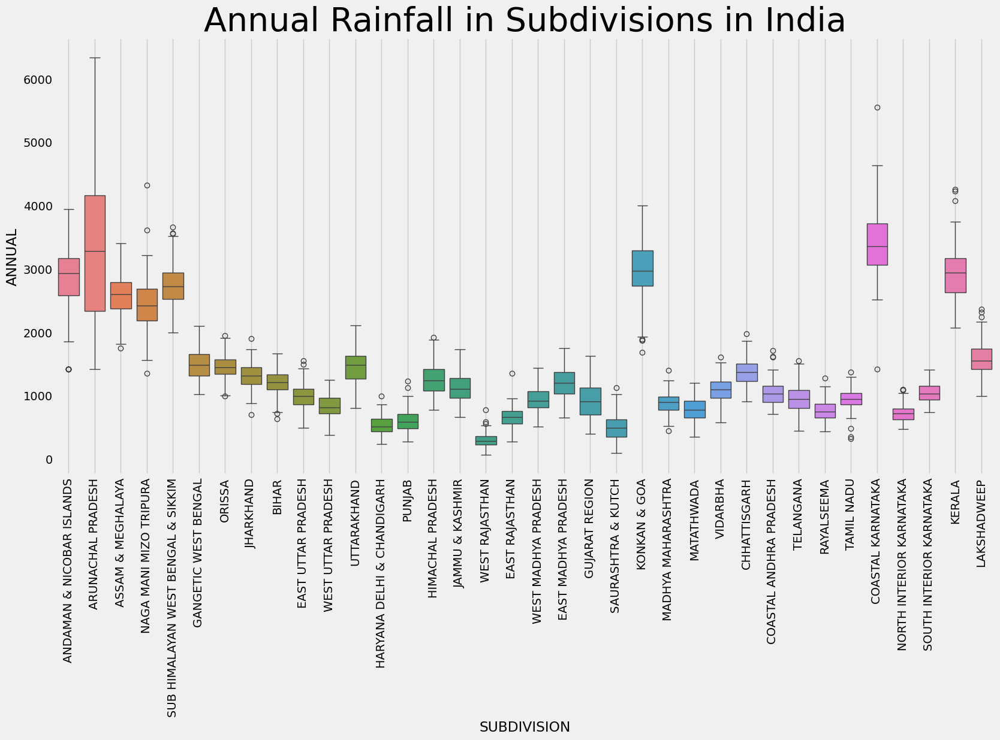

In [17]:
fig = plt.figure(figsize=(18, 9))
plt.xticks(rotation='vertical')
sns.boxplot(x='SUBDIVISION', y='ANNUAL', hue = 'SUBDIVISION', data=data)
plt.title('Annual Rainfall in Subdivisions in India',fontsize=40)
plt.grid()
plt.show()

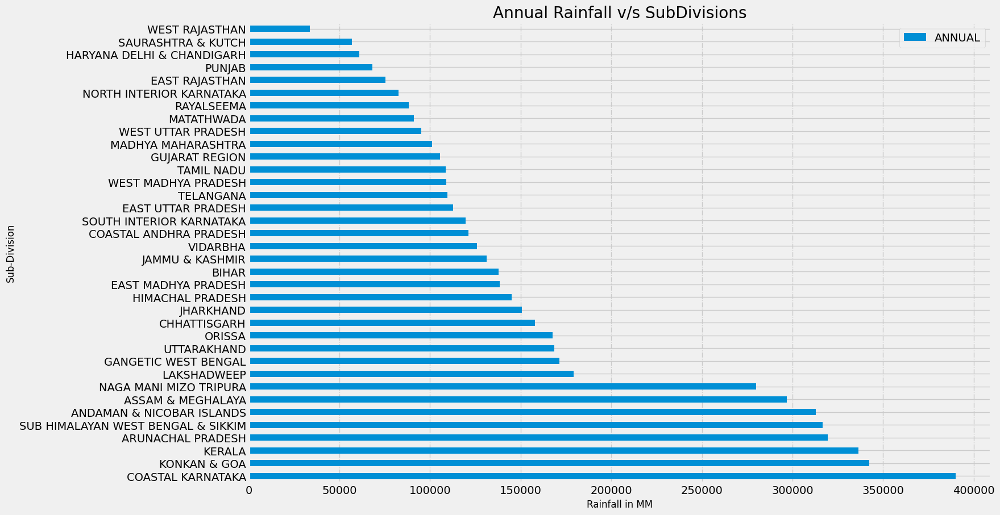

In [18]:
data[["SUBDIVISION","ANNUAL"]].groupby("SUBDIVISION").sum().sort_values(by='ANNUAL',ascending=False).plot(kind='barh',stacked=True,figsize=(15,10))
plt.xlabel("Rainfall in MM",size=12)
plt.ylabel("Sub-Division",size=12)
plt.title("Annual Rainfall v/s SubDivisions")
plt.grid(axis="x",linestyle="-.")
plt.show()

`Above plot shows the total rainfall from year 1901-2015 in each subdivision,
 from the above plot we note that:-
 1)west Rajasthan,punjab,delhi have recieved the least rainfall
 2)Rainfall was more in western states tripura,meghalaya,Arunachal Pradesh,kerala,Goa,karnatka,and also in Andaman`

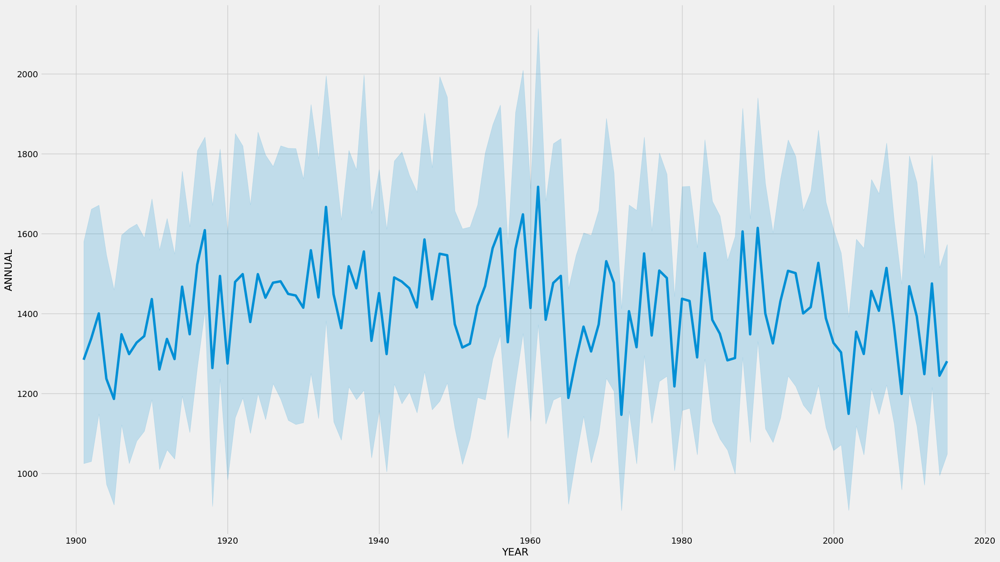

In [19]:
plt.figure(figsize=(25,15))
sns.lineplot(x = 'YEAR', y= 'ANNUAL', data = data)
plt.show()

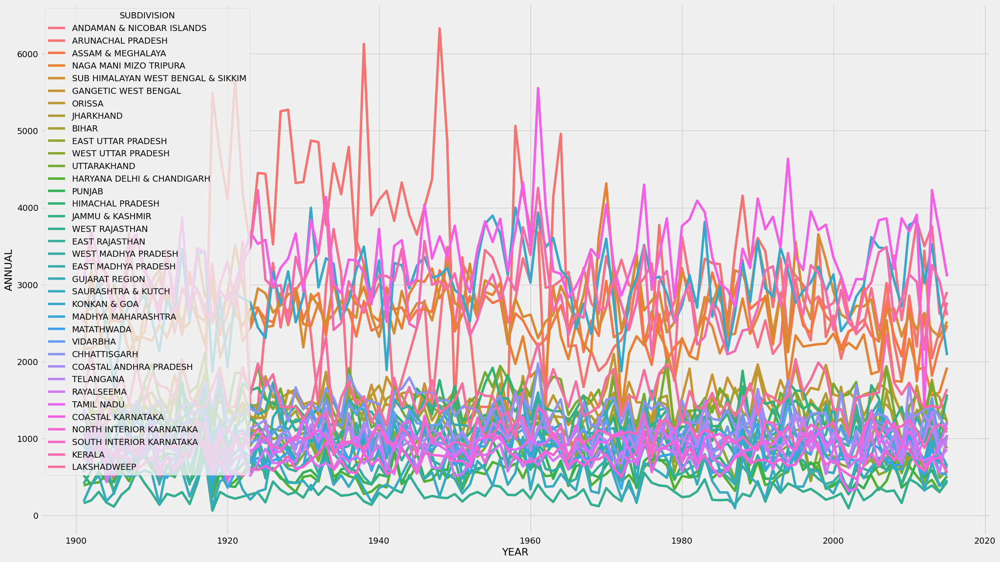

In [20]:
plt.figure(figsize=(25,15))
sns.lineplot(x = 'YEAR', y= 'ANNUAL', hue = 'SUBDIVISION', data = data)
plt.show()

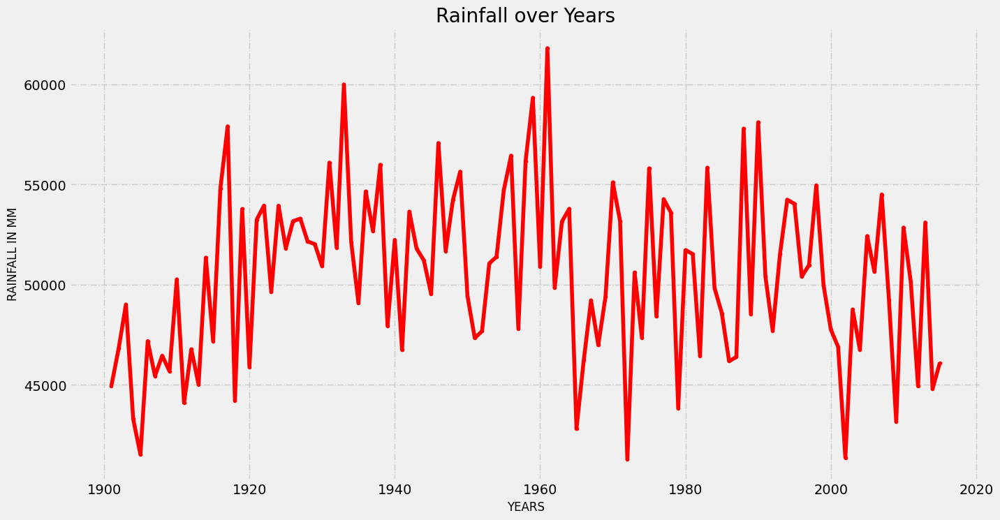

In [21]:
plt.figure(figsize=(15,8))
data.groupby("YEAR").sum()['ANNUAL'].plot(kind="line",color="r",marker=".")
plt.xlabel("YEARS",size=12)
plt.ylabel("RAINFALL IN MM",size=12)
plt.grid(axis="both",linestyle="-.")
plt.title("Rainfall over Years")
plt.show()

`Above graph shows the Rainfall from 1901-2015 in India,
 we observe that :-
 1)The maximum Rainfall was in 1950s`

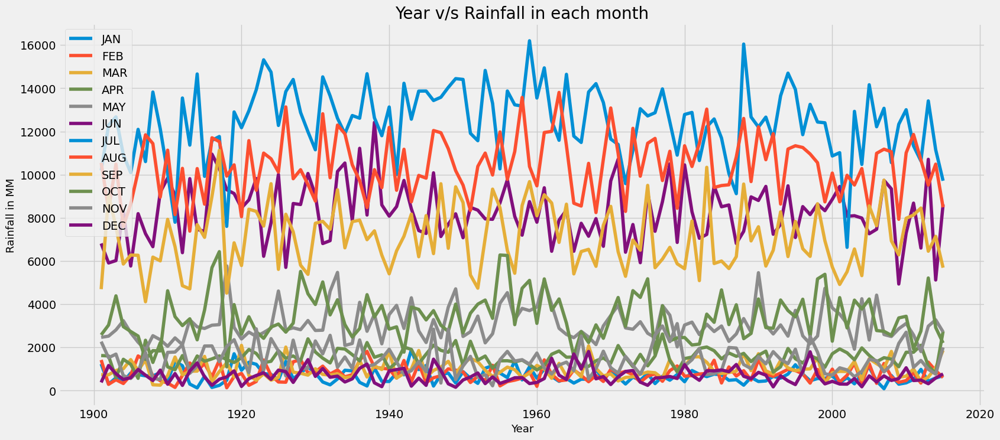

In [22]:
data[['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL','AUG', 'SEP',
      'OCT', 'NOV', 'DEC']].groupby("YEAR").sum().plot(kind="line",figsize=(18,8))
plt.xlabel("Year",size=13)
plt.ylabel("Rainfall in MM",size=13)
plt.title("Year v/s Rainfall in each month",size=20)
plt.show()

`Above plot shows the Year vs Rainfall in each month,
 we observe that:-
 1)July has heavy rainfall 
 2)Feb has least rainfall `

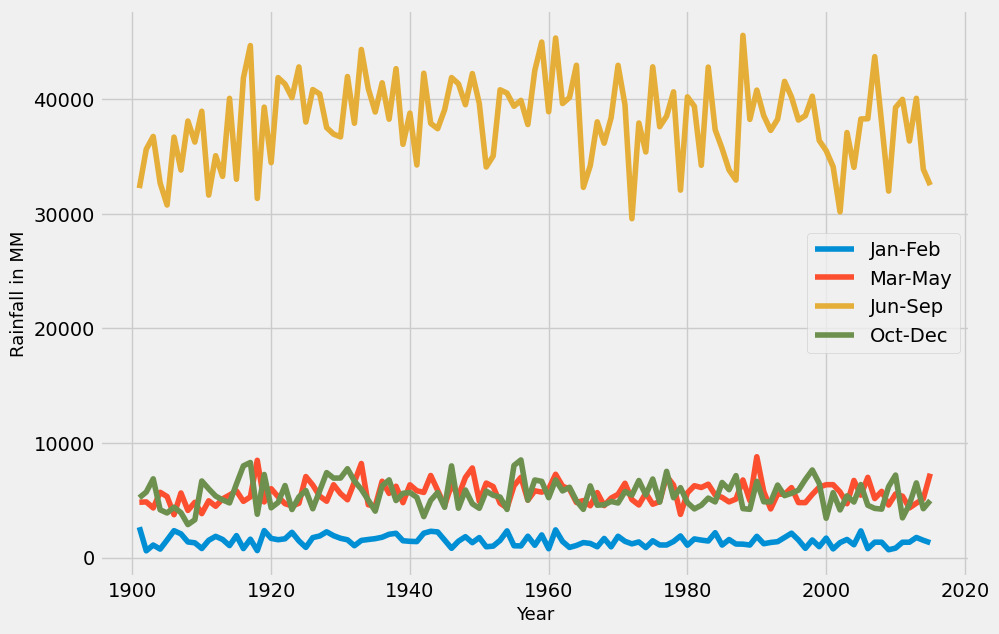

In [23]:
data[['YEAR','Jan-Feb', 'Mar-May',
       'Jun-Sep', 'Oct-Dec']].groupby("YEAR").sum().plot(figsize=(10,7))
plt.xlabel("Year",size=13)
plt.ylabel("Rainfall in MM",size=13)
plt.show()

`From Above Graph we observe that :-
 1)combined jun,july,august,sept recieves huge rainfall
 2)combined jan,feb recieves least Rainfall`

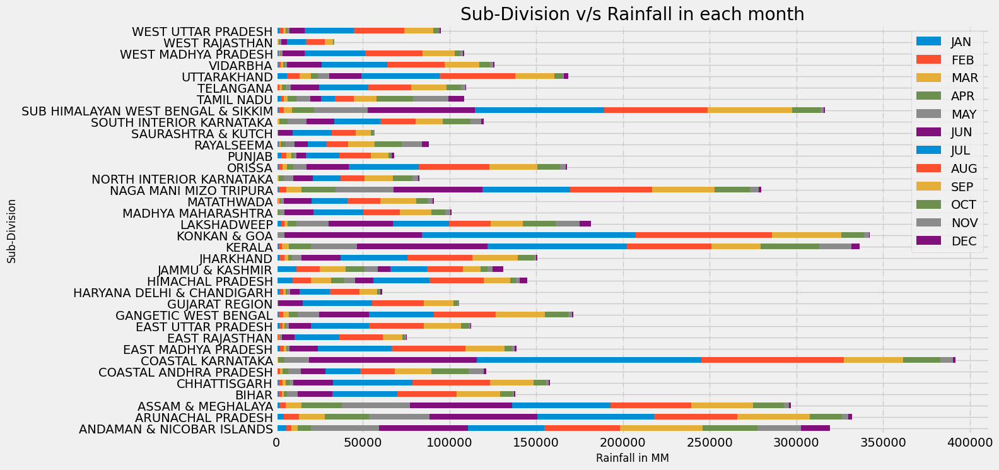

In [24]:
data[['SUBDIVISION', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL',
       'AUG', 'SEP', 'OCT', 'NOV', 'DEC']].groupby("SUBDIVISION").sum().plot(kind="barh",stacked=True,figsize=(13,8))
plt.title("Sub-Division v/s Rainfall in each month")
plt.xlabel("Rainfall in MM",size=12)
plt.ylabel("Sub-Division",size=12)
plt.grid(axis="x",linestyle="-.")
plt.show()

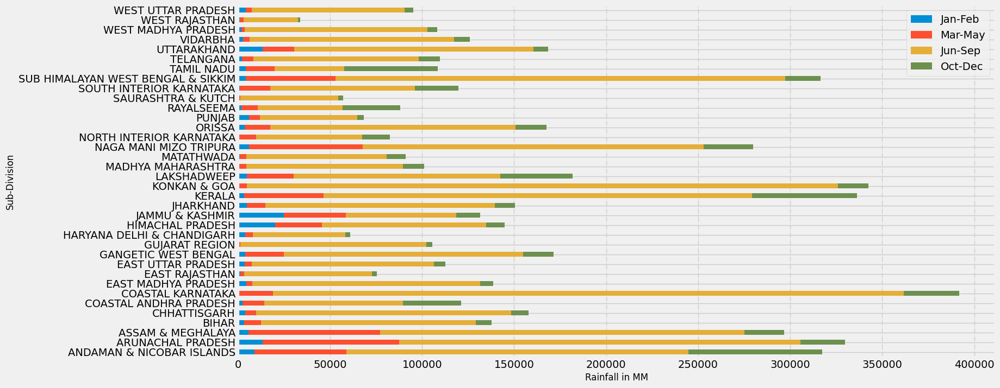

In [25]:
data[['SUBDIVISION', 'Jan-Feb', 'Mar-May',
       'Jun-Sep', 'Oct-Dec']].groupby("SUBDIVISION").sum().plot(kind="barh",stacked=True,figsize=(16,8))
plt.xlabel("Rainfall in MM",size=12)
plt.ylabel("Sub-Division",size=12)
plt.grid(axis="x",linestyle="-.")
plt.show()

`From the above two graph we observe that:-
    1)eastern states have good amont of rainfall in march,april,may`

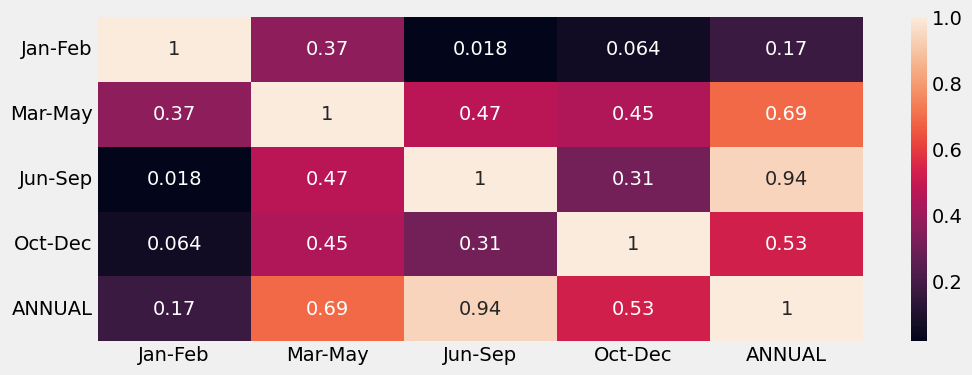

In [26]:
plt.figure(figsize=(11,4))
sns.heatmap(data[['Jan-Feb','Mar-May','Jun-Sep','Oct-Dec','ANNUAL']].corr(),annot=True)
plt.show()

array([[<Axes: title={'center': 'YEAR'}>,
        <Axes: title={'center': 'JAN'}>, <Axes: title={'center': 'FEB'}>],
       [<Axes: title={'center': 'MAR'}>, <Axes: title={'center': 'APR'}>,
        <Axes: title={'center': 'MAY'}>],
       [<Axes: title={'center': 'JUN'}>, <Axes: title={'center': 'JUL'}>,
        <Axes: title={'center': 'AUG'}>],
       [<Axes: title={'center': 'SEP'}>, <Axes: title={'center': 'OCT'}>,
        <Axes: title={'center': 'NOV'}>]], dtype=object)

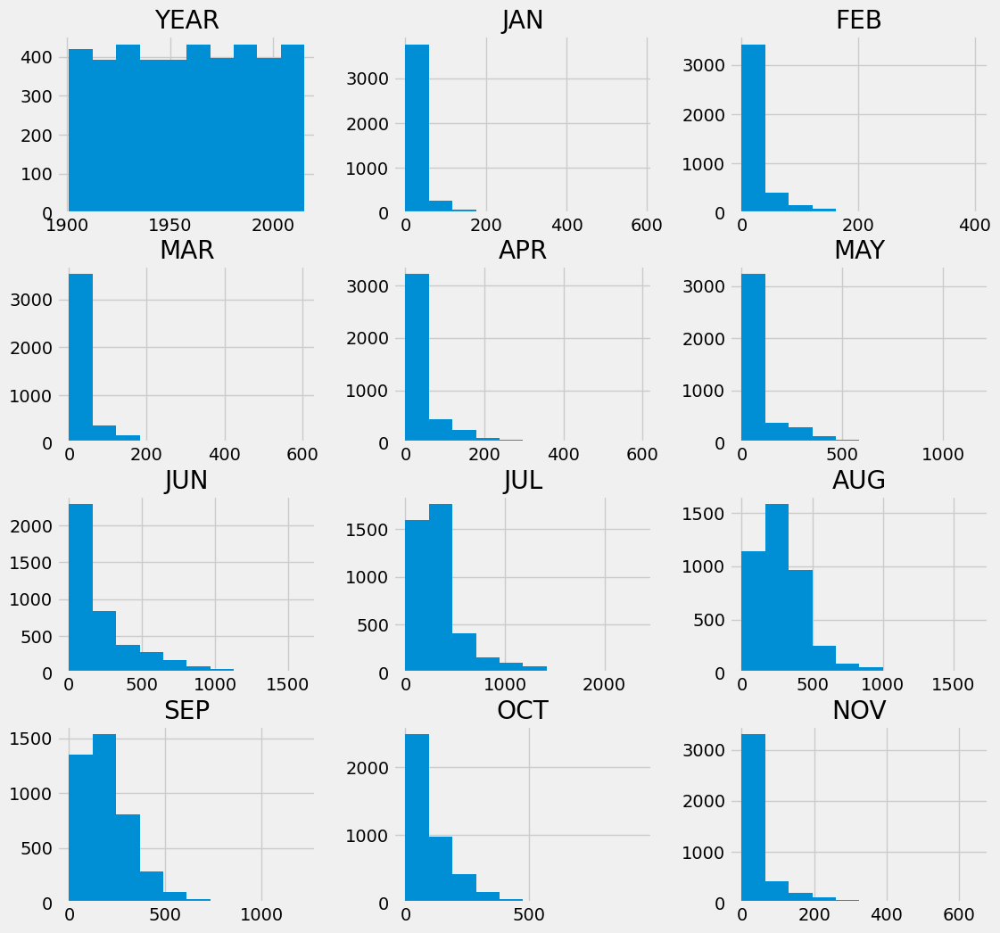

In [27]:
data.iloc[:,:13].hist(figsize=(12,12))

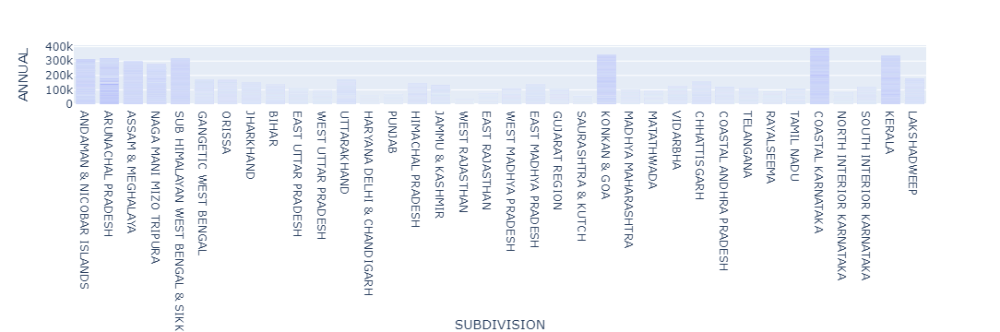

In [28]:
import plotly.express as pt
fig = pt.bar(data, x="SUBDIVISION", y="ANNUAL")
fig.show()

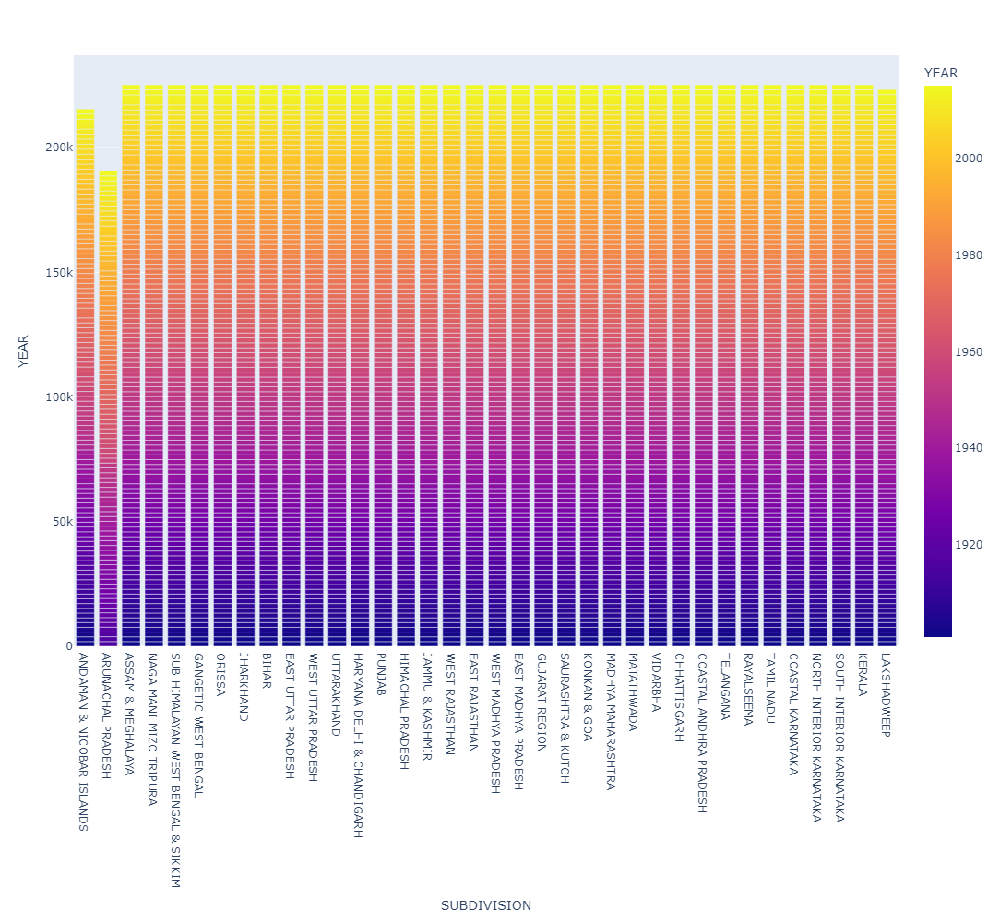

In [29]:
fig = pt.bar(data, x='SUBDIVISION', y='YEAR',
             hover_data=['ANNUAL'], color='YEAR',
             labels={'ANNUAL':'TOTAL ANNUAL RAINFALL'}, height=1000)
fig.show()

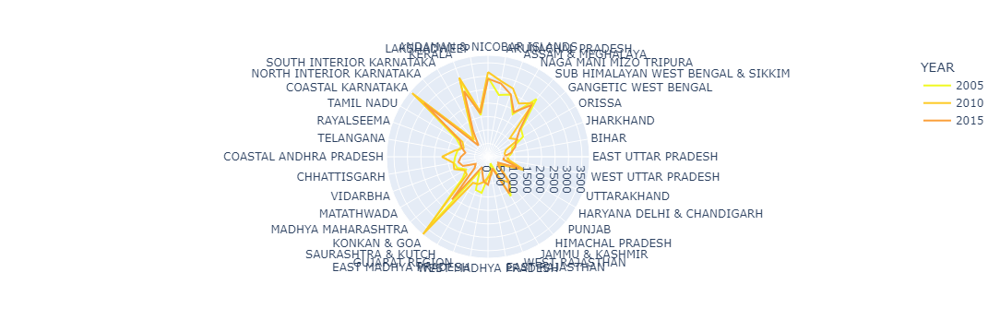

In [30]:
fig = pt.line_polar(data[(data["YEAR"]==2005) | (data["YEAR"]==2010) | (data["YEAR"]==2015)], r="ANNUAL",theta="SUBDIVISION",color='YEAR' ,line_close=True,color_discrete_sequence=pt.colors.sequential.Plasma_r,template="plotly")
fig.show()

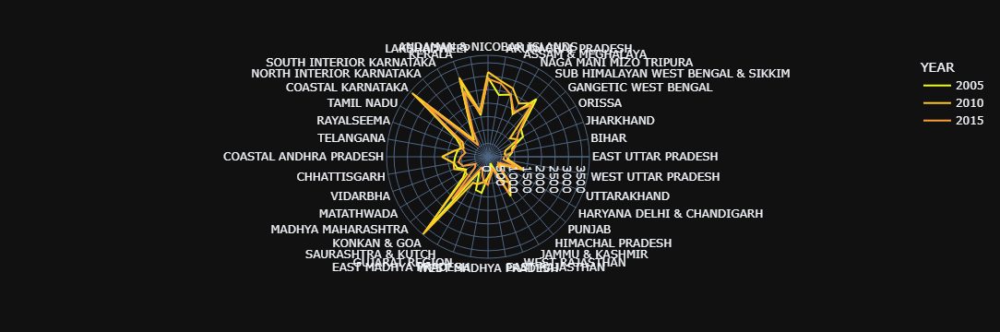

In [31]:
fig = pt.line_polar(data[(data["YEAR"]==2005) | (data["YEAR"]==2010) | (data["YEAR"]==2015)], r="ANNUAL",theta="SUBDIVISION",color='YEAR' ,line_close=True,color_discrete_sequence=pt.colors.sequential.Plasma_r,template="plotly_dark")
fig.show()

In [32]:
fig = pt.treemap(data, path=['SUBDIVISION','YEAR'], values='ANNUAL', title='Rainfall')
fig.show()

In [33]:
# from ydata_profiling import ProfileReport
# Report = ProfileReport(data)
# Report.to_file(output_file = 'Rainfall.html')
# Report

In [34]:
# Analysis of rainfall data of tamil nadu
KG = data.loc[((data['SUBDIVISION'] == 'KONKAN & GOA'))]
KG.head(4)

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
2507,KONKAN & GOA,1901,5.6,0.1,0.4,35.7,19.9,746.1,1075.5,748.0,117.4,38.6,5.4,0.1,2792.9,5.7,56.0,2687.0,44.1
2508,KONKAN & GOA,1902,0.3,0.0,0.0,0.4,7.6,428.2,943.6,515.1,613.8,74.3,42.7,48.0,2673.9,0.3,8.0,2500.6,165.0
2509,KONKAN & GOA,1903,0.0,0.0,0.1,0.0,201.1,470.5,1298.6,673.9,285.1,140.8,12.4,1.7,3084.3,0.0,201.2,2728.2,154.9
2510,KONKAN & GOA,1904,0.0,0.1,6.6,6.3,4.6,975.8,771.7,321.3,217.0,90.3,0.0,0.0,2393.7,0.1,17.5,2285.8,90.3


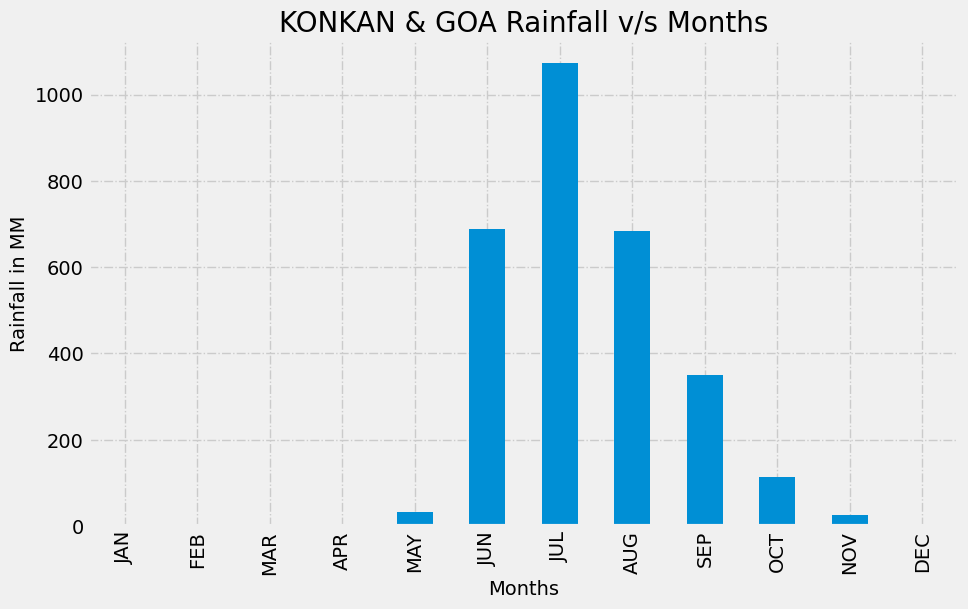

In [35]:
plt.figure(figsize=(10,6))
KG[['JAN', 'FEB', 'MAR', 'APR','MAY', 'JUN','JUL','AUG', 'SEP', 'OCT','NOV','DEC']].mean().plot(kind="bar",width=0.5,linewidth=2)
plt.title("KONKAN & GOA Rainfall v/s Months",size=20)
plt.xlabel("Months",size=14)
plt.ylabel("Rainfall in MM",size=14)
plt.grid(axis="both",linestyle="-.")
plt.show()


`From the above graph we observe that:-
 1)Tamil Nadu has good amount of rainfall in oct and nov`

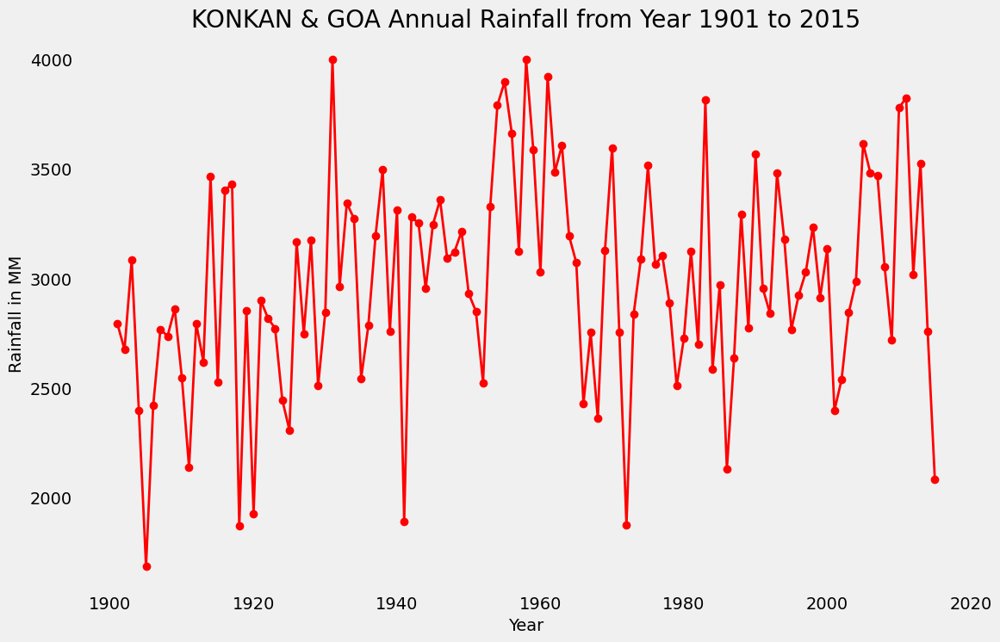

In [36]:
KG.groupby("YEAR").sum()['ANNUAL'].plot(color='r',marker='o',linestyle='-',linewidth=2,figsize=(12,8));
plt.xlabel('Year',size=14)
plt.ylabel('Rainfall in MM',size=14)
plt.title('KONKAN & GOA Annual Rainfall from Year 1901 to 2015')
plt.grid()
plt.show()

`From the Above graph we observe that:
 1)The lowest rainfall in Tamil Nadu was noted in 2002-2003
 2)and, The highest was Rainfall was noted in 2005`

In [37]:
# analysis of rainfall data of rajasthan
Maharashtra = data.loc[((data['SUBDIVISION'] == 'KONKAN & GOA') | (data['SUBDIVISION'] == 'MADHYA MAHARASHTRA') | (data['SUBDIVISION'] == 'MATATHWADA') |(data['SUBDIVISION'] == 'VIDARBHA'))]
Maharashtra.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
2507,KONKAN & GOA,1901,5.6,0.1,0.4,35.7,19.9,746.1,1075.5,748.0,117.4,38.6,5.4,0.1,2792.9,5.7,56.0,2687.0,44.1
2508,KONKAN & GOA,1902,0.3,0.0,0.0,0.4,7.6,428.2,943.6,515.1,613.8,74.3,42.7,48.0,2673.9,0.3,8.0,2500.6,165.0
2509,KONKAN & GOA,1903,0.0,0.0,0.1,0.0,201.1,470.5,1298.6,673.9,285.1,140.8,12.4,1.7,3084.3,0.0,201.2,2728.2,154.9
2510,KONKAN & GOA,1904,0.0,0.1,6.6,6.3,4.6,975.8,771.7,321.3,217.0,90.3,0.0,0.0,2393.7,0.1,17.5,2285.8,90.3
2511,KONKAN & GOA,1905,0.1,0.1,0.0,0.4,8.6,293.7,770.6,305.5,208.3,83.5,12.1,0.0,1682.8,0.2,9.0,1578.1,95.5


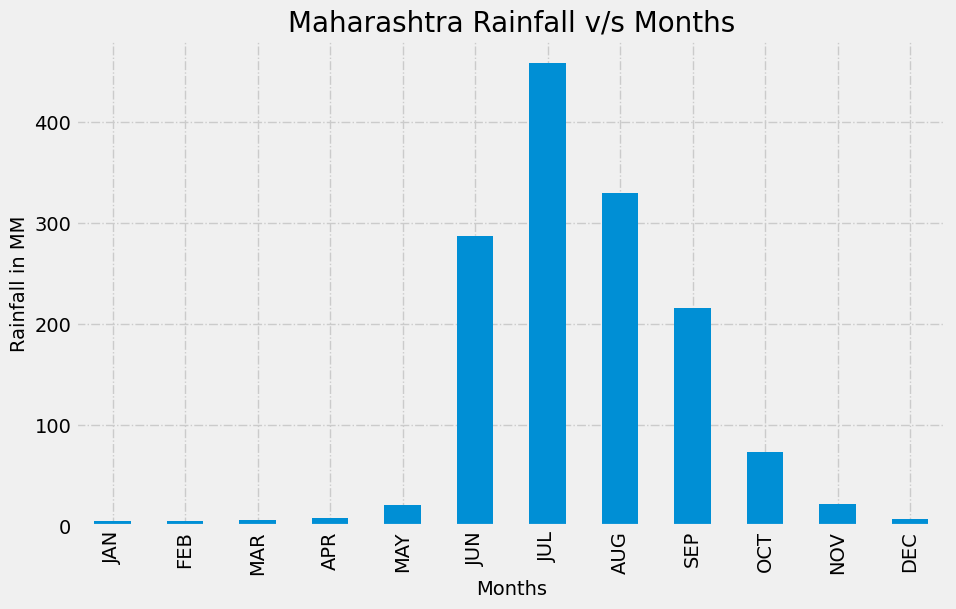

In [38]:
plt.figure(figsize=(10,6))
Maharashtra[['JAN', 'FEB', 'MAR', 'APR','MAY', 'JUN','JUL','AUG', 'SEP', 'OCT','NOV','DEC']].mean().plot(kind="bar",width=0.5,linewidth=2)
plt.title("Maharashtra Rainfall v/s Months",size=20)
plt.xlabel("Months",size=14)
plt.ylabel("Rainfall in MM",size=14)
plt.grid(axis="both",linestyle="-.")
plt.show()

`From the Above graph we observe that:-
 1)Rajasthan recieves good amount of rainfall in July and August`
 

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4548\4070165643.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



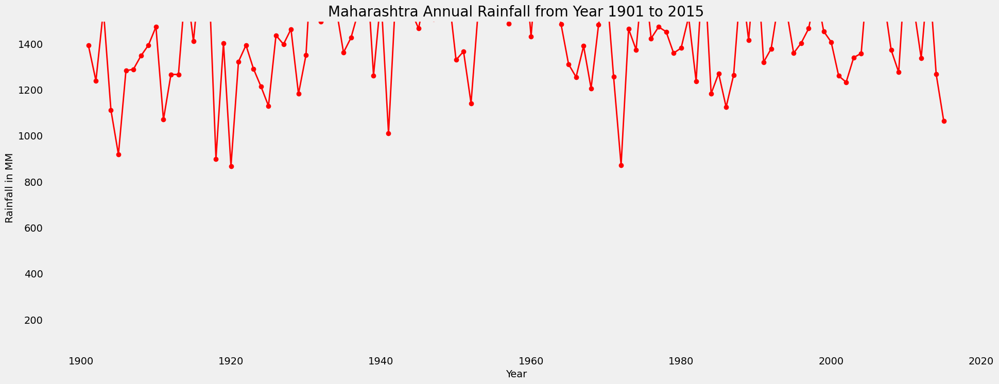

In [39]:
# import pandas as pd
# import matplotlib.pyplot as plt

# Assume 'Rajasthan' is your DataFrame

# Convert 'ANNUAL' column to numeric, handling errors
Maharashtra['ANNUAL'] = pd.to_numeric(Maharashtra['ANNUAL'], errors='coerce')

# Group by 'YEAR' and calculate the mean for 'ANNUAL'
mean_annual = Maharashtra.groupby("YEAR")['ANNUAL'].mean()

# Plotting
mean_annual.plot(ylim=(50, 1500), color='r', marker='o', linestyle='-', linewidth=2, figsize=(21, 8))
plt.xlabel('Year', size=14)
plt.ylabel('Rainfall in MM', size=14)
plt.title('Maharashtra Annual Rainfall from Year 1901 to 2015', size=20)
plt.grid()
plt.show()


`From the Above graph we note that:-
 1)The large amount of rainfall in Rajasthan was noted in year 1918`

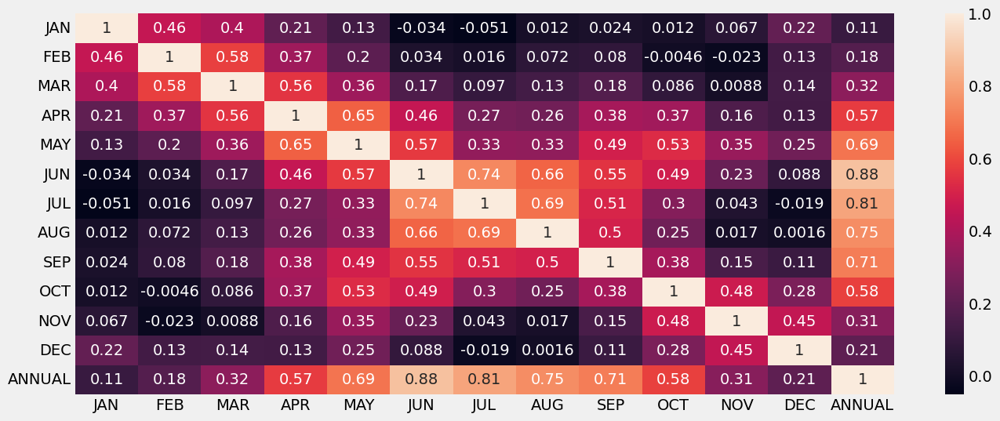

In [40]:
# correlation b/w each numeric attribute
plt.figure(figsize=(15,6))
sns.heatmap(data[['JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC','ANNUAL']].corr(),annot=True)
plt.show()

`The above heatmap shows the coorelation between different features in the dataset`

## Modelling 

In [41]:
data["SUBDIVISION"].nunique()

36

In [42]:
# Group the data by 'SUBDIVISION'
group = data.groupby('SUBDIVISION')[['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']]

# Extract the relevant subdivisions for Maharashtra
maharashtra_subdivisions = ['KONKAN & GOA', 'MADHYA MAHARASHTRA', 'MATATHWADA', 'VIDARBHA']

# Get the specific group for Maharashtra
data = data[data['SUBDIVISION'].isin(maharashtra_subdivisions)]

# Display the first few rows of the Maharashtra data
data.head()

,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
2507,KONKAN & GOA,1901,5.6,0.1,0.4,35.7,19.9,746.1,1075.5,748.0,117.4,38.6,5.4,0.1,2792.9,5.7,56.0,2687.0,44.1
2508,KONKAN & GOA,1902,0.3,0.0,0.0,0.4,7.6,428.2,943.6,515.1,613.8,74.3,42.7,48.0,2673.9,0.3,8.0,2500.6,165.0
2509,KONKAN & GOA,1903,0.0,0.0,0.1,0.0,201.1,470.5,1298.6,673.9,285.1,140.8,12.4,1.7,3084.3,0.0,201.2,2728.2,154.9
2510,KONKAN & GOA,1904,0.0,0.1,6.6,6.3,4.6,975.8,771.7,321.3,217.0,90.3,0.0,0.0,2393.7,0.1,17.5,2285.8,90.3
2511,KONKAN & GOA,1905,0.1,0.1,0.0,0.4,8.6,293.7,770.6,305.5,208.3,83.5,12.1,0.0,1682.8,0.2,9.0,1578.1,95.5


In [43]:
df=data.melt(['YEAR']).reset_index()
df.head()

,index,YEAR,variable,value
0,0,1901,SUBDIVISION,KONKAN & GOA
1,1,1902,SUBDIVISION,KONKAN & GOA
2,2,1903,SUBDIVISION,KONKAN & GOA
3,3,1904,SUBDIVISION,KONKAN & GOA
4,4,1905,SUBDIVISION,KONKAN & GOA


In [44]:
df= df[['YEAR','variable','value']].reset_index().sort_values(by=['YEAR','index'])
df.head()

,index,YEAR,variable,value
0,0,1901,SUBDIVISION,KONKAN & GOA
115,115,1901,SUBDIVISION,MADHYA MAHARASHTRA
230,230,1901,SUBDIVISION,MATATHWADA
345,345,1901,SUBDIVISION,VIDARBHA
460,460,1901,JAN,5.6


In [45]:
df.YEAR.unique()

array([1901, 1902, 1903, 1904, 1905, 1906, 1907, 1908, 1909, 1910, 1911,
       1912, 1913, 1914, 1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922,
       1923, 1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933,
       1934, 1935, 1936, 1937, 1938, 1939, 1940, 1941, 1942, 1943, 1944,
       1945, 1946, 1947, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955,
       1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966,
       1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977,
       1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988,
       1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999,
       2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010,
       2011, 2012, 2013, 2014, 2015], dtype=int64)

In [46]:
df.columns=['Index','Year','Month','Avg_Rainfall']

In [47]:
df.head()

,Index,Year,Month,Avg_Rainfall
0,0,1901,SUBDIVISION,KONKAN & GOA
115,115,1901,SUBDIVISION,MADHYA MAHARASHTRA
230,230,1901,SUBDIVISION,MATATHWADA
345,345,1901,SUBDIVISION,VIDARBHA
460,460,1901,JAN,5.6


In [48]:
Month_map={'JAN':1,'FEB':2,'MAR' :3,'APR':4,'MAY':5,'JUN':6,'JUL':7,'AUG':8,'SEP':9,
   'OCT':10,'NOV':11,'DEC':12}
df['Month']=df['Month'].map(Month_map)
df.head(12)

,Index,Year,Month,Avg_Rainfall
0,0,1901,NaN,KONKAN & GOA
115,115,1901,NaN,MADHYA MAHARASHTRA
230,230,1901,NaN,MATATHWADA
345,345,1901,NaN,VIDARBHA
460,460,1901,1.0,5.6
575,575,1901,1.0,18.8
690,690,1901,1.0,15.8
805,805,1901,1.0,36.8
920,920,1901,2.0,0.1
1035,1035,1901,2.0,0.6


In [49]:
df.drop(columns="Index",inplace=True)

In [50]:
df.head(2)

,Year,Month,Avg_Rainfall
0,1901,NaN,KONKAN & GOA
115,1901,NaN,MADHYA MAHARASHTRA


<Figure size 1200x600 with 0 Axes>

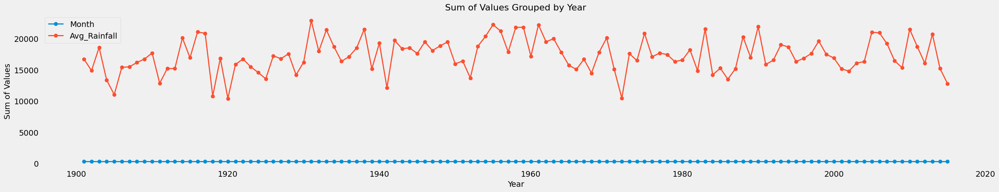

In [51]:
# Convert relevant columns to numeric, handling errors
# This assumes your DataFrame may have other numeric columns to sum
# Replace 'col1', 'col2', etc., with your actual column names
numeric_columns = df.columns.difference(['Year'])  # Get all columns except 'Year'
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')

# Grouping the DataFrame by 'Year' and summing the numeric values
grouped_data = df.groupby("Year").sum()

# Plotting the summed data
plt.figure(figsize=(12, 6))  # Set the figure size
grouped_data.plot(marker='o', linestyle='-', linewidth=2)

# Adding labels and title
plt.xlabel('Year', size=14)
plt.ylabel('Sum of Values', size=14)
plt.title('Sum of Values Grouped by Year', size=16)

# Adding a grid for better readability
plt.grid()

# Display the plot
plt.tight_layout()  # Adjust layout to make room for labels
plt.show()

In [52]:
X=np.asanyarray(df[['Year','Month']]).astype('int')
y=np.asanyarray(df['Avg_Rainfall']).astype('int')
print(X.shape)
print(y.shape)

(8280, 2)
(8280,)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4548\1550185398.py:1: RuntimeWarning:

invalid value encountered in cast

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_4548\1550185398.py:2: RuntimeWarning:

invalid value encountered in cast



In [53]:
# splitting the dataset into training and testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

### Linear Regression Model

In [54]:
from sklearn.linear_model import LinearRegression
LR = LinearRegression()
LR.fit(X_train,y_train)

LinearRegression()

In [55]:
# predicting 
y_train_predict=LR.predict(X_train)
y_test_predict=LR.predict(X_test)

In [56]:
print("-------Test Data--------")
print('MAE:', metrics.mean_absolute_error(y_test, y_test_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_test_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_test_predict)))

print("\n-------Train Data--------")
print('MAE:', metrics.mean_absolute_error(y_train,y_train_predict))
print('MSE:', metrics.mean_squared_error(y_train, y_train_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_train_predict)))

print("\n-----Training Accuracy-------")
print(round(LR.score(X_train,y_train),3)*100)
print("-----Testing Accuracy--------")
print(round(LR.score(X_test,y_test),3)*100)


-------Test Data--------
MAE: 202827240.81461748
MSE: 2.1544076562942678e+17
RMSE: 464155971.2310365

-------Train Data--------
MAE: 199294968.8429643
MSE: 2.126813193871997e+17
RMSE: 461173849.418199

-----Training Accuracy-------
11.799999999999999
-----Testing Accuracy--------
11.600000000000001


### Lasso Model

In [57]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

# Create a Lasso object
lasso = Lasso(max_iter=200000)

# Define the parameter grid for alpha
parameter = {'alpha': [1e-15, 1e-10, 1e-8, 1e-3, 1e-2, 1, 5, 1e1, 1e2, 1e3, 1e4, 1e5, 1e6, 1e7]}

# Initialize GridSearchCV with the Lasso model and parameter grid
lasso_regressor = GridSearchCV(
    lasso, parameter,
    scoring='neg_mean_squared_error',
    cv=5
)

# # Scale the features
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)

# # Fit the model to the scaled training data
# lasso_regressor.fit(X_train_scaled, y_train)

# # Print the best estimator found by GridSearchCV
# print("Best Parameter for Lasso:", lasso_regressor.best_estimator_)


In [58]:
# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Fit the model to the scaled training data
lasso_regressor.fit(X_train_scaled, y_train)


C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.733e+20, tolerance: 1.070e+17

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.068e+20, tolerance: 1.152e+17

C:\Users\Lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:697: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.973e+

GridSearchCV(cv=5, estimator=Lasso(max_iter=200000),
             param_grid={'alpha': [1e-15, 1e-10, 1e-08, 0.001, 0.01, 1, 5, 10.0,
                                   100.0, 1000.0, 10000.0, 100000.0, 1000000.0,
                                   10000000.0]},
             scoring='neg_mean_squared_error')

In [59]:
# Print the best estimator found by GridSearchCV
print("Best Parameter for Lasso:", lasso_regressor.best_estimator_)


Best Parameter for Lasso: Lasso(alpha=1000000.0, max_iter=200000)


In [60]:
lasso=Lasso(alpha=100.0,max_iter=100000)

# fit into the object
lasso.fit(X_train,y_train)

Lasso(alpha=100.0, max_iter=100000)

In [61]:
# predicting 
y_train_predict=lasso.predict(X_train)
y_test_predict=lasso.predict(X_test)

In [62]:
from sklearn import metrics
print("-------Test Data--------")
print('MAE:', metrics.mean_absolute_error(y_test, y_test_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_test_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_test_predict)))

print("\n-------Train Data--------")
print('MAE:', metrics.mean_absolute_error(y_train,y_train_predict))
print('MSE:', metrics.mean_squared_error(y_train, y_train_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_train_predict)))

print("\n-----Training Accuracy-------")
print(round(lasso.score(X_train,y_train),3)*100)
print("-----Testing Accuracy--------")
print(round(lasso.score(X_test,y_test),3)*100)


-------Test Data--------
MAE: 202827239.03219008
MSE: 2.1544076558644538e+17
RMSE: 464155971.1847359

-------Train Data--------
MAE: 199294967.09607077
MSE: 2.1268131938719965e+17
RMSE: 461173849.41819894

-----Training Accuracy-------
11.799999999999999
-----Testing Accuracy--------
11.600000000000001


### Ridge Model

In [63]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
 
ridge=Ridge()
parameters={'alpha':[1e-15,1e-10,1e-8,1e-3,1e-2,1,5,10,20,30,35,40,45,50,55,100]}
ridge_regressor=GridSearchCV(ridge,parameters,scoring='neg_mean_squared_error',cv=5)
ridge_regressor.fit(X_train,y_train)

print(ridge_regressor.best_params_)
print(ridge_regressor.best_score_)


{'alpha': 100}
-2.1316030700253334e+17


In [64]:
print("Best Parameter for Ridge:",ridge_regressor.best_estimator_)

Best Parameter for Ridge: Ridge(alpha=100)


In [65]:
ridge=Ridge(alpha=100.0)

# fit into the object
ridge.fit(X_train,y_train)

Ridge(alpha=100.0)

In [66]:
# predicting the train and test values 
y_train_predict=ridge.predict(X_train)
y_test_predict=ridge.predict(X_test)

In [67]:

from sklearn import metrics
print("-------Test Data--------")
print('MAE:', metrics.mean_absolute_error(y_test, y_test_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_test_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_test_predict)))

print("\n-------Train Data--------")
print('MAE:', metrics.mean_absolute_error(y_train,y_train_predict))
print('MSE:', metrics.mean_squared_error(y_train, y_train_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_train_predict)))

print("\n-----Training Accuracy-------")
print(round(ridge.score(X_train,y_train),3)*100)
print("-----Testing Accuracy--------")
print(round(ridge.score(X_test,y_test),3)*100)


-------Test Data--------
MAE: 202827221.19204196
MSE: 2.1544076515624906e+17
RMSE: 464155970.72131807

-------Train Data--------
MAE: 199294949.61157787
MSE: 2.1268131938720074e+17
RMSE: 461173849.41820014

-----Training Accuracy-------
11.799999999999999
-----Testing Accuracy--------
11.600000000000001


### Svm Model

In [68]:
# from sklearn import preprocessing
# from sklearn import svm

# svm_regr = svm.SVC(kernel='rbf')
# svm_regr.fit(X_train, y_train) 

In [69]:
# y_test_predict = svm_regr.predict(X_test)
# y_train_predict = svm_regr.predict(X_train)

In [70]:
# from sklearn import metrics
# print("-------Test Data--------")
# print('MAE:', metrics.mean_absolute_error(y_test, y_test_predict))
# print('MSE:', metrics.mean_squared_error(y_test, y_test_predict))
# print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_test_predict)))

# print("\n-------Train Data--------")
# print('MAE:', metrics.mean_absolute_error(y_train,y_train_predict))
# print('MSE:', metrics.mean_squared_error(y_train, y_train_predict))
# print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_train_predict)))


# print("\n-----Training Accuracy-------")
# print(round(svm_regr.score(X_train,y_train),3)*100)
# print("-----Testing Accuracy--------")
# print(round(svm_regr.score(X_test,y_test),3)*100)


### Random Forest Model

In [71]:
from sklearn.ensemble import RandomForestRegressor
random_forest_model = RandomForestRegressor(max_depth=100, max_features='sqrt', min_samples_leaf=4,
                      min_samples_split=10, n_estimators=800)
random_forest_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=100, max_features='sqrt', min_samples_leaf=4,
                      min_samples_split=10, n_estimators=800)

In [72]:
y_train_predict=random_forest_model.predict(X_train)
y_test_predict=random_forest_model.predict(X_test)

In [73]:

print("-------Test Data--------")
print('MAE:', metrics.mean_absolute_error(y_test, y_test_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_test_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_test_predict)))

print("\n-------Train Data--------")
print('MAE:', metrics.mean_absolute_error(y_train,y_train_predict))
print('MSE:', metrics.mean_squared_error(y_train, y_train_predict))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_train, y_train_predict)))

-------Test Data--------
MAE: 209471820.71508312
MSE: 2.386449873306295e+17
RMSE: 488513037.0119405

-------Train Data--------
MAE: 194434712.4753904
MSE: 2.0881436648776406e+17
RMSE: 456962106.1836135


In [74]:
print("-----------Training Accuracy------------")
print(round(random_forest_model.score(X_train,y_train),3)*100)
print("-----------Testing Accuracy------------")
print(round(random_forest_model.score(X_test,y_test),3)*100)


-----------Training Accuracy------------
13.4
-----------Testing Accuracy------------
2.0


In [75]:
predicted = random_forest_model.predict([[2016,11]])

In [76]:
predicted

array([67.24848528])

In [83]:
import numpy as np
import pandas as pd
import pickle
from sklearn import metrics

data = pd.read_csv("rainfall in india 1901-2015.csv")
data.head()

# Step 1: Select numeric columns
numeric_cols = data.select_dtypes(include='number').columns

# Step 2: Fill NaN values in numeric columns with the mean
data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].mean())


group = data.groupby('SUBDIVISION')[['YEAR','JAN','FEB','MAR','APR','MAY','JUN','JUL','AUG','SEP','OCT','NOV','DEC']]
Maharashtra = data.loc[((data['SUBDIVISION'] == 'KONKAN & GOA') | (data['SUBDIVISION'] == 'MADHYA MAHARASHTRA') | (data['SUBDIVISION'] == 'MATATHWADA') |(data['SUBDIVISION'] == 'VIDARBHA'))]
Maharashtra.head()
data=group.get_group(Maharashtra['SUBDIVISION'].iloc[0])
# data.head()

df=data.melt(['YEAR']).reset_index()
df.head()

df= df[['YEAR','variable','value']].reset_index().sort_values(by=['YEAR','index'])
df.head()

df.columns=['Index','Year','Month','Avg_Rainfall']
Month_map={'JAN':1,'FEB':2,'MAR' :3,'APR':4,'MAY':5,'JUN':6,'JUL':7,'AUG':8,'SEP':9,
   'OCT':10,'NOV':11,'DEC':12}
df['Month']=df['Month'].map(Month_map)
df.head(12)

df.drop(columns="Index",inplace=True)

X=np.asanyarray(df[['Year','Month']]).astype('int')
y=np.asanyarray(df['Avg_Rainfall']).astype('int')

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

from sklearn.ensemble import RandomForestRegressor
random_forest_model = RandomForestRegressor(max_depth=100, max_features='sqrt', min_samples_leaf=4,
                      min_samples_split=10, n_estimators=800)
random_forest_model.fit(X_train, y_train)

y_predict = random_forest_model.predict(X_test)

print('MAE:', metrics.mean_absolute_error(y_test,y_predict))
print('MSE:', metrics.mean_squared_error(y_test, y_predict))

print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_predict)))
print("-----------Training Accuracy------------")
print(round(random_forest_model.score(X_train,y_train),3)*100)
print("-----------Testing Accuracy------------")
print(round(random_forest_model.score(X_test,y_test),3)*100)

file = open("prediction.pkl","wb")
pickle.dump(random_forest_model,file)
file.close()
print(y_predict)

MAE: 85.79102046021008
MSE: 22411.631479882744
RMSE: 149.7051484748696
-----------Training Accuracy------------
90.60000000000001
-----------Testing Accuracy------------
83.6
[5.66663162e+02 5.66931894e+02 4.59128379e+01 5.22843066e+00
 7.43649547e+02 9.52464174e+02 1.52462014e+00 3.26112820e+02
 8.68125861e+02 9.69216060e+00 6.47846329e+02 9.89420507e-01
 2.97531656e+02 4.96940318e+01 4.38596951e+00 4.83518737e+00
 7.32174508e+02 6.58969282e+02 8.37533907e+02 8.16555502e+02
 4.62521005e+00 3.29401827e+01 5.13648576e+00 5.35750212e+00
 7.11542369e+02 7.51273068e+02 5.71156902e+00 3.38168168e+01
 2.62917885e+01 1.63412909e+01 9.21149159e+00 8.36010583e+02
 1.18959321e+02 2.55746394e+01 6.38522642e+00 6.14765614e+00
 4.94785360e+01 1.51550739e+00 8.81881282e+00 5.12819592e+00
 5.43457907e+00 3.42842602e+01 4.80841475e+01 3.29178133e+02
 3.31049708e+02 6.10927333e+02 5.34954663e+00 8.13853073e+02
 1.83099241e+02 2.00892599e+02 8.69259893e+00 7.06671840e+01
 5.72993914e+01 8.48988032e+02 9